# Regularization cho mạng neural

Mạng neural có nhiều tham số nên dễ học thuộc dữ liệu train, kể cả nhiễu: train loss tiếp tục giảm trong khi lỗi trên dữ liệu mới tăng lên. Regularization là các kỹ thuật hạn chế việc này: dropout tắt ngẫu nhiên một phần neuron khi train, weight decay phạt trọng số lớn, early stopping dừng huấn luyện khi validation bắt đầu xấu đi. Bài này còn học BatchNorm, lớp chạy khác nhau giữa lúc train và lúc dự đoán, nguồn lỗi hay gặp khi quên chuyển chế độ.

> **Mục tiêu**
>
> - Hiểu dropout và vì sao phải nhân với $1/(1-p)$.
> - Dùng weight decay.
> - Dùng early stopping để chọn checkpoint.
> - Biết BatchNorm chạy khác nhau ở chế độ train và eval.

## Từ “học được” tới “học thuộc”

Ta có thể giảm train loss bằng cách tăng khả năng biểu diễn (capacity), nhưng dữ liệu có cả cấu trúc và nhiễu. Khi model đủ linh hoạt để bám vào nhiễu, train tiếp tục tốt lên còn validation xấu đi. Hình sau minh họa bằng hồi quy đa thức, nơi capacity chính là bậc: generator sinh 16 điểm quanh $y=x^2$, fit các bậc khác nhau và chấm trên đường sạch. Với mạng neural, cùng hiện tượng xuất hiện theo số epoch huấn luyện, như thí nghiệm ở mục early stopping.



Regularization giảm khả năng ghi nhớ của mạng, hoặc dừng huấn luyện trước khi việc ghi nhớ xảy ra. Mọi quyết định về nó dựa vào validation, nên validation phải đo đúng tổng quát hóa: nếu train và validation chứa bản sao của cùng mẫu, khoảng cách loss nhỏ không chứng minh gì. Regularization không sửa được rò rỉ dữ liệu; kiểm cách chia trước.

Tăng capacity thì phần lỗi do bias giảm còn phần do variance tăng: 10 điểm khớp đa thức bậc 9 cho lỗi train bằng 0 mà đường cong vọt giữa các điểm. Một mạng đủ lớn còn đạt 100% train ngay cả khi nhãn bị xáo ngẫu nhiên, trong khi validation chỉ bằng đoán bừa: train tốt chưa chứng minh mạng đã học được quy luật nào.

**Hỏi nhanh.** Một đội chia ngẫu nhiên các khung hình lấy từ cùng một bộ video, nên validation có nhiều ảnh gần trùng với ảnh train. Train loss là 0.02, validation loss là 0.03. Kết luận nào hợp lý?

- A. Model tổng quát hóa tốt, có thể bỏ regularization
- B. Nên thêm regularization, vì khoảng cách vẫn còn dương
- C. Chưa kết luận được gì, phải chia lại theo video trước
- D. Validation thấp như vậy nghĩa là model đang underfit

<details><summary>Đáp án</summary>

C. Chưa kết luận được gì, phải chia lại theo video trước

Ảnh gần trùng khiến validation đo khả năng nhớ, chứ không đo khả năng tổng quát hóa. Phải chia theo nhóm (bài 1.3), để mọi khung hình của một video nằm cùng một phía. Bỏ hay thêm regularization dựa trên con số này đều là quyết định trên một thước đo đã hỏng. Underfit thì thể hiện bằng train loss cao, không phải trường hợp ở đây.

</details>

## Dropout: học khi vài đường bị bỏ

Trong training, dropout đặt mỗi phần tử activation về 0 với xác suất $p$, độc lập với nhau, và nhân các phần tử được giữ với $1/(1-p)$. Vì không neuron nào chắc chắn có mặt, mạng không thể dồn một quyết định vào một nhóm nhỏ neuron phối hợp chặt với nhau; nó phải học nhiều đường dự phòng.

Cũng có thể nhìn dropout như huấn luyện cùng lúc rất nhiều mạng con dùng chung trọng số, rồi ở eval lấy xấp xỉ trung bình của chúng; một lớp $n$ neuron có $2^n$ cách giữ bỏ, tức $2^n$ mạng con.

Nếu $h=3$, $p=0.5$, đầu ra là 0 với xác suất một nửa hoặc 6 với xác suất một nửa. Kỳ vọng $0.5\cdot0+0.5\cdot6=3$, nên thang trung bình được giữ. Đây là inverted dropout: hệ số bù nằm ở train, nên eval không bốc mask và không nhân thêm gì. Vector toàn số 1 qua `nn.Dropout(p=0.5)` ở train vì thế chỉ chứa 0 và 2.



In [ ]:
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(29)
h = torch.tensor([1., 2., 3., 4.])
mask = torch.tensor([1., 0., 1., 0.])
print('hand dropout:', (h * mask / (1 - .5)).tolist())
dropout = nn.Dropout(p=.5)
dropout.train()
first = dropout(h)
second = dropout(h)
print('train 1:', first.tolist())
print('train 2:', second.tolist())
dropout.eval()
print('eval:', dropout(h).tolist())

hand dropout: [2.0, 0.0, 6.0, 0.0]
train 1: [0.0, 4.0, 6.0, 8.0]
train 2: [2.0, 0.0, 6.0, 0.0]
eval: [1.0, 2.0, 3.0, 4.0]


Hai vector train khác nhau dù cùng đầu vào, vì RNG đã tiến sang mask mới; seed cố định giúp lặp lại cả chuỗi thí nghiệm. Lượt thứ nhất giữ ba trên bốn phần tử, lượt thứ hai giữ hai: tỉ lệ bỏ $p$ chỉ đúng trung bình, không đúng ở từng lượt. Vector eval trở về $[1,2,3,4]$.

Hai cơ chế cần tách bạch: `model.train()`/`model.eval()` đổi hành vi layer, còn `torch.no_grad()` chỉ ngừng ghi graph. Gọi `no_grad` mà model vẫn ở train thì dropout vẫn bốc mask; gọi eval thì gradient vẫn tính được nếu cần. Dạng hàm `F.dropout(x, p=0.5)` không biết `model.eval()`; nó mặc định `training=True`, nên phải truyền `training=self.training` hoặc dùng layer `nn.Dropout`.

**Hỏi nhanh.** Dropout với $p = 0.2$. Một activation bằng 4 được giữ lại trong lượt train. Sau dropout, giá trị của nó là bao nhiêu?

- A. 3.2
- B. 4
- C. 5
- D. 20

<details><summary>Đáp án</summary>

C. 5

Inverted dropout chia cho $1 - p = 0.8$, nên $4/0.8 = 5$. Nhân với $0.8$ là phép bù của dropout kiểu cũ, đặt nhầm chỗ. Giữ nguyên 4 thì thang lúc train thấp hơn lúc eval. Chia cho $p$ là nhầm xác suất bỏ với xác suất giữ. Hệ số này giữ đúng giá trị kỳ vọng, chứ không giữ đầu ra của từng mask.

</details>

**Hỏi nhanh.** Một đội tự cài dropout theo kiểu bài báo gốc: lúc train chỉ nhân mask với $p = 0.5$, không chia cho $1 - p$. Khi eval tắt mask, phải làm gì để thang activation khớp với lúc train?

- A. Giữ nguyên activation, như inverted dropout
- B. Nhân activation với $1 - p$
- C. Chia activation cho $1 - p$
- D. Vẫn bốc mask $p = 0.5$ như lúc train

<details><summary>Đáp án</summary>

B. Nhân activation với $1 - p$

Lúc train, kỳ vọng của activation là $(1 - p)h$. Eval dùng mọi neuron, nên phải nhân với $1 - p$ để về cùng thang. Inverted dropout chuyển phép bù sang lúc train, nhờ vậy eval không phải sửa gì, nên giữ nguyên chỉ đúng với kiểu inverted. Chia cho $1 - p$ là làm ngược chiều. Bốc mask lúc eval thì dự đoán thành ngẫu nhiên.

</details>

## Weight decay: hạn chế trọng số quá lớn

Weight decay tác động lên tham số, còn dropout tác động ngẫu nhiên lên activation. Với SGD, thêm $\frac{\lambda}{2}\lVert\mathbf w\rVert^2$ vào loss tạo gradient phụ $\lambda w$, nên mỗi bước là

$$w\leftarrow w-\eta\left(\frac{\partial \ell}{\partial w}+\lambda w\right)=(1-\eta\lambda)\,w-\eta\frac{\partial \ell}{\partial w}.$$

AdamW tách riêng phép co $w\leftarrow(1-\eta\lambda)w$ khỏi bước thích nghi; bài 3.5 đã phân biệt hai cách. Trọng số nào không được dữ liệu kéo lên sẽ bị co dần về 0, nên mạng chỉ giữ trọng số lớn ở chỗ thật sự giảm loss. Hai cơ chế dùng được cùng nhau, nhưng quá nhiều regularization làm cả train lẫn validation kém, vì model không còn đủ sức học cấu trúc.

Không có một giá trị decay chung cho mọi bài. Lượng co tích lũy phụ thuộc rate, số step, kiến trúc và lượng dữ liệu; nếu rate đổi theo scheduler, hệ số co mỗi step đổi theo. Vì vậy cần ghi cấu hình đầy đủ khi so, và dò decay trên thang log.

Một mô hình nhỏ, dữ liệu sạch có thể không cần dropout. Thêm kỹ thuật chỉ vì có trong danh sách không tự tạo ra cải thiện; hãy đo trên validation.

**Hỏi nhanh.** AdamW với `weight_decay=0.1`. Scheduler giảm learning rate từ 0.01 xuống 0.001 ở epoch 30. Hệ số co trọng số ở mỗi bước thay đổi thế nào?

- A. Giữ ở $0.9$, vì `weight_decay` không đổi
- B. Từ $0.9$ thành $0.99$
- C. Từ $0.999$ thành $0.99$
- D. Từ $0.999$ thành $0.9999$

<details><summary>Đáp án</summary>

D. Từ $0.999$ thành $0.9999$

Hệ số co là $1 - \eta\lambda$: lúc đầu $1 - 0.01\cdot 0.1 = 0.999$, sau đó $1 - 0.001\cdot 0.1 = 0.9999$. Tức là phép co yếu đi mười lần cùng với learning rate. Đọc `weight_decay=0.1` thành hệ số $1 - \lambda$ cho mỗi bước là quên mất $\eta$. Chọn $0.99$ là nhầm chiều thay đổi, vì learning rate nhỏ đi thì co ít hơn.

</details>

## Early stopping dùng validation để chọn thời điểm

Thay vì học tới số epoch đã ấn định rồi lấy model cuối, ta đánh giá validation định kỳ và giữ checkpoint tốt nhất. Patience là số lần đánh giá liên tiếp không cải thiện thì dừng. `min_delta` là mức cải thiện tối thiểu được tính là tiến bộ, để những dao động rất nhỏ không kéo dài huấn luyện mãi. Epoch tốt nhất nằm trước epoch dừng đúng patience lần đánh giá, nên lúc dừng phải khôi phục trạng thái tốt nhất, không lấy trạng thái cuối.

**Hỏi nhanh.** Early stopping với patience 3 và min_delta 0.01: một lần đánh giá chỉ tính là cải thiện nếu thấp hơn loss tốt nhất ít nhất 0.01. Validation loss sau epoch 1 đến 6 là 0.50, 0.46, 0.455, 0.453, 0.452, 0.451. Huấn luyện dừng sau epoch nào?

- A. Sau epoch 4
- B. Sau epoch 5
- C. Sau epoch 6
- D. Không dừng, vì loss vẫn giảm sau mỗi epoch

<details><summary>Đáp án</summary>

B. Sau epoch 5

Tốt nhất là 0.46, ở epoch 2. Epoch 3, 4, 5 chỉ thấp hơn 0.46 từ 0.005 đến 0.008, chưa đủ 0.01, nên là ba lần liên tiếp không cải thiện, và hết patience sau epoch 5. Chọn epoch 4 là đếm thiếu một lần, epoch 6 là đếm thừa. Nếu min_delta bằng 0 thì đúng là không dừng, và min_delta có mặt chính là để chặn kiểu tiến bộ lặt vặt này.

</details>



Ta chạy một mạng nhỏ trên 16 điểm có nhiễu và chấm trên 64 điểm sạch từ cùng quy tắc $x^2$; validation sạch đo đúng phần cấu trúc mà mạng học được. Mỗi bước dùng cả 16 điểm, tức một epoch. Hai lần chạy cùng khởi tạo và ngân sách 160 epoch, chỉ đổi decay; hàm trả về lịch sử loss để vẽ đường học:

In [ ]:
g = torch.Generator().manual_seed(9)
x_train = torch.linspace(-1, 1, 16).unsqueeze(1)
y_train = x_train.square() + .18 * torch.randn(16, 1, generator=g)
x_valid = torch.linspace(-1, 1, 64).unsqueeze(1)
y_valid = x_valid.square()
print('noise MSE:', round((y_train - x_train.square()).square().mean().item(), 4))

def fit_small(decay):
    torch.manual_seed(29)
    model = nn.Sequential(nn.Linear(1, 16), nn.Tanh(),
                          nn.Linear(16, 16), nn.Tanh(), nn.Linear(16, 1))
    opt = torch.optim.AdamW(model.parameters(), lr=.02, weight_decay=decay)
    best = float('inf')
    best_epoch = -1
    best_state = None
    history = []
    for epoch in range(160):
        model.train()
        opt.zero_grad(set_to_none=True)
        train_loss = (model(x_train) - y_train).square().mean()
        train_loss.backward()
        opt.step()
        model.eval()
        with torch.no_grad():
            valid_loss = (model(x_valid) - y_valid).square().mean().item()
        history.append((train_loss.item(), valid_loss))
        if valid_loss < best:
            best, best_epoch = valid_loss, epoch + 1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return best_epoch, best, history

for decay in [0., .1]:
    epoch, best, history = fit_small(decay)
    print('decay:', decay, 'best epoch:', epoch, 'best MSE:', round(best, 5),
          'last MSE:', round(history[-1][1], 5), 'last train:', round(history[-1][0], 4))

noise MSE: 0.0491
decay: 0.0 best epoch: 26 best MSE: 0.00367 last MSE: 0.01294 last train: 0.0359
decay: 0.1 best epoch: 26 best MSE: 0.00364 last MSE: 0.0121 last train: 0.0361




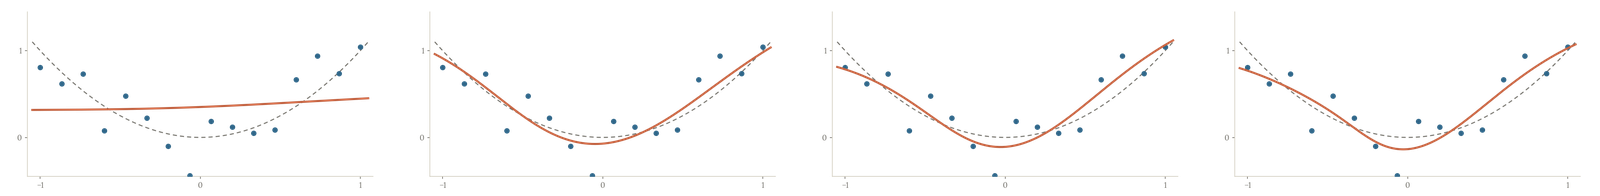

Trong cả hai lần, validation tốt nhất ở epoch 26, còn sau 160 epoch MSE validation gấp hơn ba lần. Dòng `noise MSE` cho biết vì sao: MSE của riêng nhiễu trên 16 điểm train là 0.0491, nên ngay cả hàm đúng $x^2$ cũng chỉ đạt train loss chừng ấy. Train loss cuối 0.0359 thấp hơn mức này, nghĩa là mạng đã khớp một phần nhiễu. Validation thấp hơn train vì nó chấm trên đường sạch, không phải dấu hiệu bất thường.

Khôi phục checkpoint tốt nhất lấy lại toàn bộ khoảng chênh giữa epoch tốt nhất và epoch cuối. Decay 0.1 chỉ dời best từ 0.00367 xuống 0.00364 và last từ 0.01294 xuống 0.0121, nhỏ hơn nhiều so với khoảng chênh ấy: trong thí nghiệm này, chọn đúng thời điểm quan trọng hơn decay.

Hình còn cho thấy validation dao động mạnh quanh epoch 20–40 và điểm tốt nhất là một đáy hẹp: chọn điểm thấp nhất trên một đường nhiễu cho con số hơi lạc quan. Validation ở đây đã dùng để chọn epoch và decay, nên không còn là ước lượng độc lập; muốn báo chất lượng sau khi chọn, cần một tập test chưa dùng để chọn.

**Hỏi nhanh.** Với decay bằng 0, MSE tốt nhất là 0.00367 ở epoch 26, còn MSE ở epoch cuối là 0.01294. Một bạn đề xuất lần sau train 500 epoch “cho chắc”, rồi nộp model cuối. Nên sửa đề xuất thế nào?

- A. Theo dõi validation, nộp checkpoint tốt nhất
- B. Giữ nguyên, vì train càng lâu thì train loss càng thấp
- C. Chỉ cần tăng decay lên 0.1 rồi nộp model cuối
- D. Cố định đúng 26 epoch rồi bỏ hẳn validation

<details><summary>Đáp án</summary>

A. Theo dõi validation, nộp checkpoint tốt nhất

Tới epoch 160, validation MSE đã gấp hơn ba lần mức tốt nhất, trong khi train loss vẫn giảm. Phần train thêm chủ yếu là học nhiễu. Decay 0.1 cho MSE cuối là 0.0121, vẫn tệ hơn mức tốt nhất rất nhiều. Cố định 26 epoch chỉ đúng với seed và dữ liệu này. Theo dõi validation thì mới tự tìm được điểm dừng khi điều kiện thay đổi.

</details>

## BatchNorm có trạng thái riêng

BatchNorm chuẩn hóa các activation theo thống kê một batch trong train, rồi học hệ số scale $\gamma$ và shift $\beta$. Với mỗi feature,

$$\hat x=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\varepsilon}},\qquad y=\gamma\hat x+\beta.$$

Với feature $[1,3]$, mean là 2, phương sai chia $B$ là 1. Khi $\gamma=2$, $\beta=1$ và bỏ qua $\varepsilon$ để tính trên giấy, hai đầu ra là $-1$ và $3$. $\gamma$, $\beta$ cho phép layer học lại thang và độ dời phù hợp; chuẩn hóa không bắt buộc mọi feature cuối luôn mean 0 và variance 1 sau affine.

Nó còn giữ running mean/variance (trung bình trượt của mean, variance) để dùng ở eval. Đây là buffer của model, cũng được lưu trong `state_dict`. Khác scaler tính một lần từ train, thống kê BatchNorm cập nhật sau mỗi lượt forward ở chế độ train theo trung bình trượt

$$\hat\mu\leftarrow(1-m)\,\hat\mu+m\,\mu_B,$$

với $m$ là `momentum` (mặc định 0.1) và $\hat\mu$ bắt đầu từ 0; running variance cập nhật cùng cách, bắt đầu từ 1. Momentum ở đây là trọng số của thống kê mới, không cùng công thức với momentum của optimizer.

Vài chi tiết:

- Validation phải chạy ở eval để các buffer ấy không hấp thụ thông tin validation.
- Số $\varepsilon$ nhỏ trong $\sqrt{\sigma^2+\varepsilon}$ tránh chia cho 0 khi một feature gần như không đổi trong batch.
- Phép trừ mean xóa mọi hằng số cộng vào trước, nên Linear hay Conv ngay trước BatchNorm không cần bias; $\beta$ đã làm việc ấy.

Để nhìn rõ phép số, tắt affine và dùng `momentum=1`, tức running statistics nhận toàn bộ thống kê batch mới. Dữ liệu gồm hai hàng $(1,2)$ và $(3,4)$. Mean là $(2,3)$; phương sai dùng chuẩn hóa train là $(1,1)$. PyTorch ghi running variance bằng ước lượng không chệch, ở batch này là $(2,2)$, nên eval cùng input không nhất thiết trùng train.

In [ ]:
batch = torch.tensor([[1., 2.], [3., 4.]])
bn = nn.BatchNorm1d(2, affine=False, momentum=1.)
bn.train()
train_output = bn(batch)
print('train:', [[round(v, 4) for v in row] for row in train_output.tolist()])
print('running mean:', bn.running_mean.tolist())
print('running variance:', bn.running_var.tolist())
bn.eval()
eval_output = bn(batch)
print('eval:', [[round(v, 4) for v in row] for row in eval_output.tolist()])

train: [[-1.0, -1.0], [1.0, 1.0]]
running mean: [2.0, 3.0]
running variance: [2.0, 2.0]
eval: [[-0.7071, -0.7071], [0.7071, 0.7071]]


Train gần $(-1,-1),(1,1)$; eval gần $(-1/\sqrt2,-1/\sqrt2),(1/\sqrt2,1/\sqrt2)$, sai lệch nhỏ do epsilon. Khác biệt đến từ hai công thức phương sai: chia $B$ khi chuẩn hóa, chia $B-1$ khi ghi running variance. Với batch thật lớn hơn và momentum 0.1, running statistics là trung bình trượt qua nhiều batch, nên eval ổn định và dự đoán một mẫu không phụ thuộc mẫu nào đứng cùng batch.



**Hỏi nhanh.** Ở chế độ eval, một BatchNorm mặc định, tức `track_running_stats=True`, chuẩn hóa input bằng thống kê nào?

- A. Mean và variance của batch eval đang chạy
- B. Running mean và running variance đã học trong lúc train
- C. Mean 0 và variance 1, cố định từ lúc khởi tạo
- D. Mean và variance fit lại trên toàn tập test

<details><summary>Đáp án</summary>

B. Running mean và running variance đã học trong lúc train

Running statistics được cập nhật trong lúc train và cố định khi eval, nên dự đoán cho một mẫu không phụ thuộc vào các mẫu đứng cùng batch. Dùng thống kê của batch đang chạy là cách hoạt động lúc train. 0 và 1 chỉ là điểm xuất phát của trung bình trượt. Fit trên test là đưa dữ liệu test vào model.

</details>

**Hỏi nhanh.** `nn.BatchNorm1d` mặc định, `momentum=0.1`, vừa khởi tạo nên running mean bằng 0. Sau một lượt forward ở chế độ train với một batch có mean bằng 2, running mean bằng bao nhiêu?

- A. 0.2
- B. 1.8
- C. 2
- D. 0, vì running mean chỉ cập nhật khi eval

<details><summary>Đáp án</summary>

A. 0.2

$(1 - 0.1)\cdot 0 + 0.1\cdot 2 = 0.2$. Ra 1.8 là hiểu ngược momentum thành trọng số của giá trị cũ. Ra 2 là trường hợp momentum bằng 1, như ví dụ ở trên. Running statistics cập nhật lúc train và đứng yên lúc eval, chứ không phải ngược lại.

</details>

## BatchNorm trong mạng sâu

Mục đích ban đầu của BatchNorm là ổn định tối ưu, không phải regularization. Mỗi lớp nhận input có thang ổn định dù trọng số các lớp trước đang đổi, nên mạng sâu học được với learning rate lớn hơn. Bài 3.3 đã đo tín hiệu co theo cấp số nhân qua 10 lớp ReLU khởi tạo $\mathcal N(0,0.01^2)$ và sửa bằng khởi tạo He, tức sửa từ phía trọng số. Thí nghiệm sau giữ nguyên khởi tạo nhỏ ấy, chỉ chèn BatchNorm sau mỗi Linear, rồi đo độ lệch chuẩn của activation sau lớp 1, 5 và 10:

In [ ]:
def deep_relu(use_bn):
    torch.manual_seed(0)
    layers = []
    for _ in range(10):
        linear = nn.Linear(64, 64)
        nn.init.normal_(linear.weight, std=.01)
        nn.init.zeros_(linear.bias)
        layers += [linear, nn.BatchNorm1d(64), nn.ReLU()] if use_bn else [linear, nn.ReLU()]
    return nn.Sequential(*layers)

x = torch.randn(128, 64, generator=torch.Generator().manual_seed(1))
for use_bn in [False, True]:
    h, stds = x, []
    for layer in deep_relu(use_bn):
        h = layer(h)
        if isinstance(layer, nn.ReLU):
            stds.append(h.std().item())
    name = 'with BatchNorm:' if use_bn else 'plain:'
    print(name, ' '.join(f'{stds[i]:.1e}' for i in (0, 4, 9)))

plain: 4.7e-02 4.9e-07 2.0e-13
with BatchNorm: 5.8e-01 5.8e-01 5.9e-01


Không có BatchNorm, tín hiệu co khoảng $0.01\cdot\sqrt{64/2}\approx0.057$ lần mỗi lớp (hệ số của bài 3.3 với 64 đầu vào), nên sau 10 lớp chỉ còn cỡ $10^{-13}$ và gradient về các lớp đầu tắt theo. Có BatchNorm, trọng số vẫn nhỏ như cũ nhưng mỗi lớp được đưa về mean 0, variance 1 trước ReLU, nên độ lệch chuẩn giữ quanh 0.58 ở mọi độ sâu.

He đặt đúng thang một lần lúc khởi tạo; BatchNorm chỉnh lại ở mỗi lớp trong suốt quá trình train, kể cả khi trọng số đã trôi khỏi thang ban đầu. Với mạng rất sâu, residual connection (Transformer ở bài 3.9, ResNet ở bài 5.2) còn mở đường tắt cho gradient; gradient clipping xử lý chiều ngược lại, khi gradient phình quá lớn.



Hiệu ứng regularization của BatchNorm là phụ: mean và variance của mỗi batch phụ thuộc những mẫu được bốc chung, nên trong train cùng một mẫu nhận nhiễu nhỏ khác nhau ở mỗi batch.

Khi kết hợp với dropout cần để ý thứ tự. Inverted dropout giữ mean nhưng làm variance của activation trong train lớn hơn ở eval; nếu dropout đặt ngay trước BatchNorm, running variance học trong train không khớp với variance thật lúc eval. Vì vậy dropout thường đặt sau phần có BatchNorm, chẳng hạn trước lớp phân loại cuối. Khối thường gặp là `Linear → BatchNorm → ReLU`, hoặc `Conv → BatchNorm → ReLU` ở mạng ảnh.

**Hỏi nhanh.** Cùng một ảnh nằm trong hai batch train khác nhau cho ra hai activation sau BatchNorm khác nhau, dù trọng số chưa đổi. Nhận định nào đúng?

- A. Lỗi cài đặt, vì BatchNorm phải cho cùng kết quả mọi lúc
- B. Lỗi, vì running statistics bị ghi sai sau mỗi batch
- C. Bình thường, vì BatchNorm bốc mask ngẫu nhiên như dropout
- D. Bình thường, vì thống kê của batch thay đổi, tạo ra một chút nhiễu có ích

<details><summary>Đáp án</summary>

D. Bình thường, vì thống kê của batch thay đổi, tạo ra một chút nhiễu có ích

Lúc train, mean và variance được lấy từ các mẫu đang đứng chung batch, nên đầu ra của một mẫu phụ thuộc vào các mẫu còn lại. Nhiễu ấy là một hiệu ứng regularization phụ của BatchNorm. BatchNorm không có mask, và running statistics không tham gia forward lúc train. Khi eval, running statistics cố định, nên đầu ra phải giống nhau; nếu lúc eval vẫn khác thì mới là lỗi.

</details>

## Batch nhỏ, LayerNorm và GroupNorm

BatchNorm1d nhận bảng `(B,C)` hoặc dữ liệu `(B,C,L)` và tính một mean cho mỗi kênh, gộp qua các mẫu trong batch. Với bảng chỉ một mẫu trong train, không có gì để gộp và PyTorch báo lỗi; batch rất nhỏ thì thống kê nhiễu tới mức làm hỏng huấn luyện. Cách xử lý: chọn batch đủ lớn, bỏ batch cuối kích thước 1 (`drop_last=True` trong DataLoader), hoặc chuẩn hóa trong từng mẫu.

LayerNorm tính mean/variance trên các feature của **một mẫu**, nên không phụ thuộc batch, giống nhau ở train và eval, và không có running statistics; Transformer dùng nó. GroupNorm làm tương tự trên từng nhóm kênh của ảnh. Tensor `(B, T, C)` qua `nn.LayerNorm(C)` được chuẩn hóa trên chiều $C$, riêng cho từng cặp $(b, t)$; nhân cả vector đầu vào với một số dương thì đầu ra không đổi.

Thống kê của BatchNorm tính trên batch mà layer thật sự thấy. Chạy song song 8 GPU, mỗi GPU 4 ảnh, thì mỗi GPU chuẩn hóa trên 4 ảnh của nó, trừ khi dùng SyncBatchNorm. Tích lũy gradient 8 bước batch 32 cũng cho gradient như batch 256 nhưng BatchNorm vẫn chỉ thấy 32 mẫu mỗi lượt. Khi chỉ chứa được vài ảnh mỗi batch, như phân đoạn ảnh lớn, thay bằng GroupNorm; khi tinh chỉnh mạng đã học sẵn với batch nhỏ, giữ các lớp BatchNorm ở chế độ eval để đóng băng thống kê cũ.



**Hỏi nhanh.** Tensor `x` có shape `(32, 10)`: 32 mẫu, 10 feature. Lúc train, `nn.BatchNorm1d(10)` và `nn.LayerNorm(10)` lần lượt tính bao nhiêu giá trị mean?

- A. Cả hai đều 10
- B. Cả hai đều 32
- C. BatchNorm tính 10, LayerNorm tính 32
- D. BatchNorm tính 32, LayerNorm tính 10

<details><summary>Đáp án</summary>

C. BatchNorm tính 10, LayerNorm tính 32

BatchNorm gộp theo chiều batch: mỗi feature một mean, lấy trên 32 mẫu. LayerNorm gộp theo chiều feature: mỗi mẫu một mean, lấy trên 10 feature. Tham số `10` của cả hai đều là số feature, nên dễ tưởng chúng gộp theo cùng một chiều. $\gamma$ và $\beta$ của cả hai đều có 10 phần tử.

</details>

## Khi đi thi

- So train và validation chấm cùng chế độ eval trước khi thêm regularization.
- Lưu checkpoint tốt nhất theo validation và nộp từ checkpoint đó, không từ model cuối.
- Gọi `model.eval()` trước khi dự đoán; dự đoán hai lần cùng input phải giống hệt.

## Tóm tắt

- Dropout bỏ ngẫu nhiên activation trong train và giữ kỳ vọng bằng hệ số $1/(1-p)$; eval không bỏ gì.
- Weight decay co tham số mỗi step theo $1-\eta\lambda$.
- Early stopping chọn thời điểm theo validation và khôi phục checkpoint tốt nhất.
- BatchNorm chuẩn hóa theo batch lúc train, dùng running statistics lúc eval; nó giữ thang tín hiệu ổn định qua mạng sâu. LayerNorm chuẩn hóa trong từng mẫu.
- Quên `model.eval()` là lỗi hay gặp: dropout vẫn bật, BatchNorm vẫn dùng thống kê batch.

## Kiểm tra cuối bài

**Câu 1.** Train một mạng sâu 10 lớp. Độ lớn gradient theo từng lớp, từ epoch 1 đến epoch 50, như sau. Lớp 1, gần đầu vào: 0.0003 xuống 0.0001. Lớp 5: 0.0012 xuống 0.0008. Lớp 10, ở đầu ra: 0.85 lên 1.23. Đây là vấn đề gì, và sửa cách nào hiệu quả nhất?

- A. Learning rate quá cao ở các lớp đầu, nên dùng learning rate riêng cho từng lớp
- B. Thống kê của BatchNorm bất ổn, nên tăng batch hoặc dùng GroupNorm
- C. Vanishing gradient ở các lớp đầu, nên thêm residual connection
- D. Exploding gradient ở lớp ra, nên clip độ lớn gradient về 1

<details><summary>Đáp án</summary>

C. Vanishing gradient ở các lớp đầu, nên thêm residual connection

Độ lớn gradient giảm dần từ đầu ra về đầu vào, chênh nhau hàng nghìn lần, và ở lớp 1 còn nhỏ đi theo thời gian. Các lớp đầu gần như không học. Residual connection cho gradient một đường tắt vượt qua các lớp ở giữa. Learning rate quá cao thường làm loss dao động hay nổ tung, không làm gradient lớp đầu nhỏ dần. BatchNorm bất ổn do batch nhỏ thì biểu hiện bằng loss nhiễu và chênh lệch giữa train với eval, không phải bằng sự suy giảm đều theo độ sâu. Gradient lớp ra cỡ 1 là bình thường, chưa phải exploding.
Đề thi: [NOAI 2026 Singapore · Chung kết · Câu 8](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=12)

</details>

**Câu 2.** Một MLP 12 lớp học rất chậm với learning rate 0.001, còn với 0.01 thì loss nổ tung. Chèn BatchNorm sau mỗi lớp Linear thì mạng học ổn định với 0.01 và hội tụ nhanh hơn hẳn, trong khi khoảng cách giữa train và validation gần như không đổi. Ở đây, vai trò chính của BatchNorm là gì?

- A. Đưa trọng số mỗi lớp về độ dài 1, giống weight decay
- B. Chuẩn hóa input của mỗi lớp, giúp tối ưu ổn định
- C. Chuẩn hóa loss theo batch, nên gradient khó nổ
- D. Regularize giống dropout, nhờ nhiễu theo batch

<details><summary>Đáp án</summary>

B. Chuẩn hóa input của mỗi lớp, giúp tối ưu ổn định

BatchNorm đưa input của mỗi lớp về cùng một thang theo thống kê của batch, rồi học lại $\gamma$, $\beta$. Thang ấy ổn định dù trọng số các lớp trước thay đổi, nên learning rate lớn hơn không còn làm loss nổ. Khoảng cách giữa train và validation không đổi cho thấy lợi ích nằm ở việc tối ưu, không phải ở việc chống học thuộc. Nhiễu theo batch chỉ là hiệu ứng phụ. BatchNorm không đụng vào trọng số như weight decay, và cũng không biến đổi loss. Gradient vẫn có thể lớn, nên gradient clipping vẫn có chỗ dùng.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 181](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=67)

</details>

**Câu 3.** `Dropout(p=0.5)` đặt ngay trước `BatchNorm1d` không có affine. Input của dropout luôn có mean 0, variance 1. Sau khi train lâu, running variance của BatchNorm xấp xỉ bao nhiêu, và lúc eval thì đầu ra của BatchNorm ra sao?

- A. Khoảng 1, đầu ra lúc eval có cùng thang với lúc train
- B. Khoảng 0.5, đầu ra lúc eval phình ra, variance khoảng 2
- C. Khoảng 2, đầu ra lúc eval có cùng thang với lúc train
- D. Khoảng 2, đầu ra lúc eval co lại, variance khoảng 0.5

<details><summary>Đáp án</summary>

D. Khoảng 2, đầu ra lúc eval co lại, variance khoảng 0.5

Lúc train, phần tử được giữ lại bị nhân 2, nên $\mathbb E[\tilde h^2] = 0.5\cdot 4\cdot 1 = 2$. Mean vẫn bằng 0, nên variance là 2, và running variance tiến về 2. Lúc eval dropout tắt, input chỉ có variance 1 nhưng vẫn bị chia cho $\sqrt2$, nên đầu ra có variance khoảng 0.5 thay vì 1 như lúc train. Đây là xung đột giữa hai lớp: dropout làm thống kê lúc train khác lúc eval, còn BatchNorm lại giả định chúng như nhau. Running variance bằng 1 là quên hệ số $1/(1 - p)$. Bằng 0.5 là tưởng dropout làm variance giảm.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 195](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=71)

</details>

**Câu 4.** Bài phân loại ảnh X-quang độ phân giải cao, GPU chỉ chứa được batch 2 ảnh. Model dùng BatchNorm cho điểm validation dao động mạnh giữa các epoch, và lệch nhiều giữa train với eval. Hướng sửa nào hợp lý nhất?

- A. Đặt `momentum=1` để running statistics bám sát batch mới
- B. Dùng GroupNorm hoặc LayerNorm, vốn chuẩn hóa trong từng mẫu
- C. Bỏ `model.eval()` để lúc eval cũng dùng thống kê của batch
- D. Tắt affine của BatchNorm để bớt tham số phải học

<details><summary>Đáp án</summary>

B. Dùng GroupNorm hoặc LayerNorm, vốn chuẩn hóa trong từng mẫu

Với hai mẫu, mean và variance của batch là những ước lượng rất nhiễu, và running statistics lấy trung bình những ước lượng ấy, nên lệch với từng ảnh lúc eval. LayerNorm và GroupNorm gộp bên trong một mẫu, không phụ thuộc kích thước batch, và tính như nhau lúc train lẫn eval. Momentum bằng 1 khiến running statistics chỉ nhớ batch cuối, càng nhiễu hơn. Bỏ eval làm dự đoán phụ thuộc vào ảnh nào đứng cùng batch. Affine không phải nguồn gây nhiễu.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 196](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=72)

</details>

**Câu 5.** Một đội tự viết BatchNorm cho bảng `(B, C)`. Chấm validation cả tập trong một batch 512 mẫu thì điểm tốt. Nhưng hệ thống chấm gọi model từng mẫu một ở chế độ eval, và mọi dự đoán đều giống hệt nhau. Lỗi nằm ở đâu?
```py
def forward(self, x):
    mean, var = x.mean(0), x.var(0, unbiased=False)
    if self.training:
        with torch.no_grad():
            self.running_mean.mul_(1 - self.momentum).add_(self.momentum * mean)
            self.running_var.mul_(1 - self.momentum).add_(self.momentum * var)
    x_hat = (x - mean) / torch.sqrt(var + self.eps)
    return self.gamma * x_hat + self.beta
```

- A. Thiếu `.detach()` khi cập nhật running statistics
- B. Running variance phải dùng ước lượng không chệch
- C. Lúc eval, code vẫn dùng mean và variance của batch đang chạy
- D. Momentum bị đảo, phải nhân `momentum` với giá trị cũ

<details><summary>Đáp án</summary>

C. Lúc eval, code vẫn dùng mean và variance của batch đang chạy

Running statistics có được cập nhật, nhưng không bao giờ được dùng: lúc eval, code vẫn lấy `mean`, `var` của chính batch. Với một mẫu, `x - mean` bằng 0, nên đầu ra luôn là `beta`, và mọi dự đoán như nhau. Với batch 512 mẫu, thống kê của batch gần với running statistics, nên lỗi bị che đi. Sửa bằng cách lúc eval dùng `self.running_mean` và `self.running_var`. Phép cập nhật đã nằm trong `no_grad` nên không cần `detach`. Chia cho $B$ hay $B - 1$ chỉ làm thang lệch nhẹ. Công thức momentum khớp với quy ước của PyTorch.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 9](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=13)

</details>

**Câu 6.** Loss của một mạng được cộng thêm số hạng $\frac{\lambda}{2}\lVert\mathbf w\rVert^2$, với $\lambda = 0.5$, và cập nhật bằng SGD với $\eta = 0.1$. Một trọng số $w = 2$ có đạo hàm của phần loss dữ liệu là $\partial\ell/\partial w = 0.3$. Sau một bước, $w$ bằng bao nhiêu?

- A. 1.87
- B. 1.97
- C. 2.07
- D. 0.97

<details><summary>Đáp án</summary>

A. 1.87

$w - \eta(\partial\ell/\partial w + \lambda w) = 2 - 0.1\cdot(0.3 + 1) = 1.87$. Có thể hiểu là co $w$ thành $(1 - 0.05)\cdot 2 = 1.9$, rồi trừ thêm $0.03$. Ra 1.97 là quên số hạng regularization. Ra 2.07 là đổi dấu số hạng $\lambda w$. Ra 0.97 là trừ $\lambda w$ mà quên nhân $\eta$.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q4.4(c)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=19)

</details>

**Câu 7.** Một MLP có train loss 0.01, validation loss 0.35, và validation tăng dần từ epoch 20 trong khi train vẫn giảm. Làm gì thì nhiều khả năng giảm được lỗi trên test nhất?

- A. Train thêm 200 epoch cho train loss về hẳn 0
- B. Thêm lớp và tăng độ rộng cho mạng biểu diễn mạnh hơn
- C. Bỏ dropout để mạng dùng hết khả năng biểu diễn
- D. Tăng weight decay vừa phải, rồi kiểm trên validation

<details><summary>Đáp án</summary>

D. Tăng weight decay vừa phải, rồi kiểm trên validation

Train rất thấp, validation cao và đang tăng là overfit, nên cần giảm khả năng ghi nhớ: regularization mạnh hơn, thêm dữ liệu, hoặc dừng sớm. Train thêm là đi tiếp theo hướng validation đang xấu đi. Thêm sức chứa hay bỏ dropout đều làm mạng dễ học thuộc hơn. Mức decay vẫn phải chọn trên validation, vì mạnh quá sẽ chuyển sang underfit.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q3.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=12)

</details>

**Câu 8.** Một đội thử `weight_decay` lần lượt là 0.01, 0.1, 1 và 10. Với mỗi giá trị, họ train rồi chấm lỗi trên tập test có nhãn, và chọn 0.01 vì lỗi test thấp nhất. Thấy lỗi test tăng đều theo decay, một bạn đề nghị thử thêm 0.001 và 0.0001, cũng chấm trên test. Nhận xét nào đúng?

- A. Hợp lý, vì lỗi test thấp hơn nghĩa là model tốt hơn
- B. Mở rộng vùng thử là đúng, nhưng phải chọn trên validation
- C. Không cần thử, vì decay dưới 0.01 luôn gây overfit
- D. Nên chọn decay theo lỗi train thấp nhất thay cho test

<details><summary>Đáp án</summary>

B. Mở rộng vùng thử là đúng, nhưng phải chọn trên validation

Giá trị tốt nhất nằm ở biên thì mở rộng vùng thử về phía giá trị nhỏ là đúng. Cái sai là dùng test để chọn: sau nhiều lần chọn, lỗi test của cấu hình thắng là một ước lượng quá lạc quan, không còn đo khả năng trên dữ liệu mới. Hãy chọn bằng validation hoặc cross-validation, và chỉ chấm test một lần ở cuối. Lỗi train luôn ưu tiên decay nhỏ nhất, nên không dùng để chọn được. Cũng không có ngưỡng decay nào “luôn” gây overfit.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q3.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=12)

</details>

**Câu 9.** Đội A dùng early stopping: patience 5 trên validation loss, dừng lại rồi khôi phục checkpoint tốt nhất. Đội B dùng `ReduceLROnPlateau`: mỗi khi validation không cải thiện trong 5 epoch thì chia learning rate cho 10, train đủ 100 epoch và nộp model cuối. Câu nào đúng?

- A. Hai cách tương đương, vì cùng theo dõi validation
- B. Cả hai đều là early stopping, chỉ khác tên gọi
- C. Chỉ đội A dùng validation để chọn thời điểm dừng
- D. Chỉ đội B chống được overfit, vì learning rate nhỏ thì không học được nhiễu

<details><summary>Đáp án</summary>

C. Chỉ đội A dùng validation để chọn thời điểm dừng

Early stopping là một kiểu regularization: dừng khi validation thôi cải thiện, và dùng trạng thái tốt nhất. Đội B chỉ đổi lịch learning rate. Họ vẫn train đủ 100 epoch và nộp model cuối, có thể đã overfit. Learning rate nhỏ làm bước nhỏ đi, chứ không ngăn mạng tiếp tục bám theo nhiễu. Hai kỹ thuật khác nhau, và dùng được cùng lúc.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 8](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=2)

</details>

**Câu 10.** Hàm validation chạy trong `torch.no_grad()` nhưng quên `model.eval()`. Model có Dropout và BatchNorm mặc định. Trong lúc chấm validation, chuyện gì xảy ra?

- A. Dropout vẫn bốc mask, và BatchNorm cập nhật running statistics
- B. Không có gì, vì `no_grad` đã tắt cả dropout lẫn BatchNorm
- C. Chỉ dropout bốc mask, BatchNorm không cập nhật khi thiếu gradient
- D. Chỉ BatchNorm cập nhật running statistics, vì `no_grad` đã tắt dropout

<details><summary>Đáp án</summary>

A. Dropout vẫn bốc mask, và BatchNorm cập nhật running statistics

`no_grad` chỉ ngừng ghi graph, còn chế độ của các lớp do `train()` hay `eval()` quyết định. Ở chế độ train, dropout làm điểm validation thành ngẫu nhiên. BatchNorm thì vừa chuẩn hóa bằng thống kê của batch validation, vừa ghi chúng vào running statistics, tức checkpoint đã nhận thông tin của validation. Running statistics là buffer được cập nhật trong forward, không cần gradient.

</details>

## Đọc thêm

- Srivastava và cộng sự — [Dropout](https://www.jmlr.org/papers/v15/srivastava14a.html): đọc mục tiêu tránh phụ thuộc một nhóm feature cố định.
- Ioffe, Szegedy — [Batch Normalization](https://proceedings.mlr.press/v37/ioffe15.html): bài gốc về layer chuẩn hóa có affine học được.
- [PyTorch 2.9 — Dropout](https://docs.pytorch.org/docs/2.9/generated/torch.nn.Dropout.html) và [BatchNorm1d](https://docs.pytorch.org/docs/2.9/generated/torch.nn.BatchNorm1d.html): tra train/eval, running variance và momentum đúng theo thư viện.